# AI-Powered Job Market Intelligence & Salary Prediction System
## Step 7: Skill Gap Analysis & Recommendation Engine (Module 4)

**Target Notebook:** `notebooks/07_skill_gap_analysis.ipynb`  
**Core Module:** `src/skill_analyzer.py`  
**Input Dataset:** `data/processed/cleaned_job_market_all.csv` (30,250 verified job postings)  

### Objectives & Analytical Methodology:
1. **Empirical Job Market Demand Profiling:** Calculate overall technical skill demand, frequencies, and percentages across 30,250 job postings without double-counting duplicate skills within the same posting.
2. **Dynamic Job Role Benchmarking:** Filter and aggregate skill requirements dynamically across the 12 canonical tech job roles (e.g. Data Scientist, Cloud Engineer, Software Engineer).
3. **Skill Prioritization Tiers:** Categorize role requirements into project-defined demand thresholds:
   - **Essential Skills:** Demand $\ge 50\%$
   - **Important Skills:** Demand $\ge 25\%$ and $< 50\%$
   - **Additional Skills:** Demand $< 25\%$
4. **Demand-Weighted Skill Match Scoring:** Formulate an intelligent, transparent match score weighted by market demand:
   $$\text{Skill Match Score} = \left( \frac{\sum_{s \in \text{Matched}} \text{Demand}(s)}{\sum_{s \in \text{Required}} \text{Demand}(s)} \right) \times 100$$
5. **Personalized Learning Pathways:** Diagnose missing skills, prioritize essential gaps, and generate actionable learning recommendations and project practice assignments.

In [1]:
# 1. Environment Setup & Library Imports
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.skill_analyzer import (
    SkillGapAnalyzer,
    get_available_job_roles,
    analyze_market_skill_demand,
    get_role_required_skills,
    compare_candidate_skills,
    calculate_skill_match_score,
    generate_learning_recommendations,
    generate_skill_gap_report,
    get_dataset,
)
from src.resume_parser import extract_skills_from_text

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

print('Skill Gap Analysis module imported successfully.')

Skill Gap Analysis module imported successfully.


### 2. Loading Cleaned Job Market Dataset
Ingesting `data/processed/cleaned_job_market_all.csv` and inspecting available canonical job roles.

In [2]:
df = get_dataset()
available_roles = get_available_job_roles(df)

print(f'Total Job Postings Loaded: {len(df):,}')
print(f'Total Distinct Canonical Tech Roles: {len(available_roles)}')
print('Available Job Roles:')
for i, role in enumerate(available_roles, 1):
    postings_count = len(df[df['clean_role'] == role])
    print(f'  {i:2d}. {role:<26} ({postings_count:,} postings)')

Total Job Postings Loaded: 30,250
Total Distinct Canonical Tech Roles: 12
Available Job Roles:
   1. AI Engineer                (2,470 postings)
   2. BI Developer               (2,586 postings)
   3. Business Analyst           (2,604 postings)
   4. Cloud Engineer             (2,562 postings)
   5. Data Analyst               (2,480 postings)
   6. Data Engineer              (2,542 postings)
   7. Data Scientist             (2,497 postings)
   8. MLOps Engineer             (2,500 postings)
   9. Machine Learning Engineer  (2,487 postings)
  10. NLP Engineer               (2,489 postings)
  11. Python Developer           (2,505 postings)
  12. Software Engineer          (2,528 postings)


### 3. Overall Market Skill Demand Analysis
Aggregating skill frequencies across all 30,250 job postings without double-counting duplicate skills within the same posting.

In [3]:
overall_demand = analyze_market_skill_demand(df, top_n=20)
print('Top 10 Most Demanded Technical Skills in Indian Tech Market:')
overall_demand.head(10)

Top 10 Most Demanded Technical Skills in Indian Tech Market:


,skill,job_count,demand_percentage
0,Python,10439,34.51
1,Machine Learning,10426,34.47
2,Django,5050,16.69
3,Pandas,5015,16.58
4,Git,4991,16.50
5,Flask,4990,16.50
6,Azure,4980,16.46
7,dbt,4958,16.39
8,Computer Vision,4947,16.35
9,Scikit-learn,4943,16.34


### 4. Visualizing Top 20 In-Demand Skills
Generating and saving Figure `reports/figures/market_skill_demand_top20.png`.

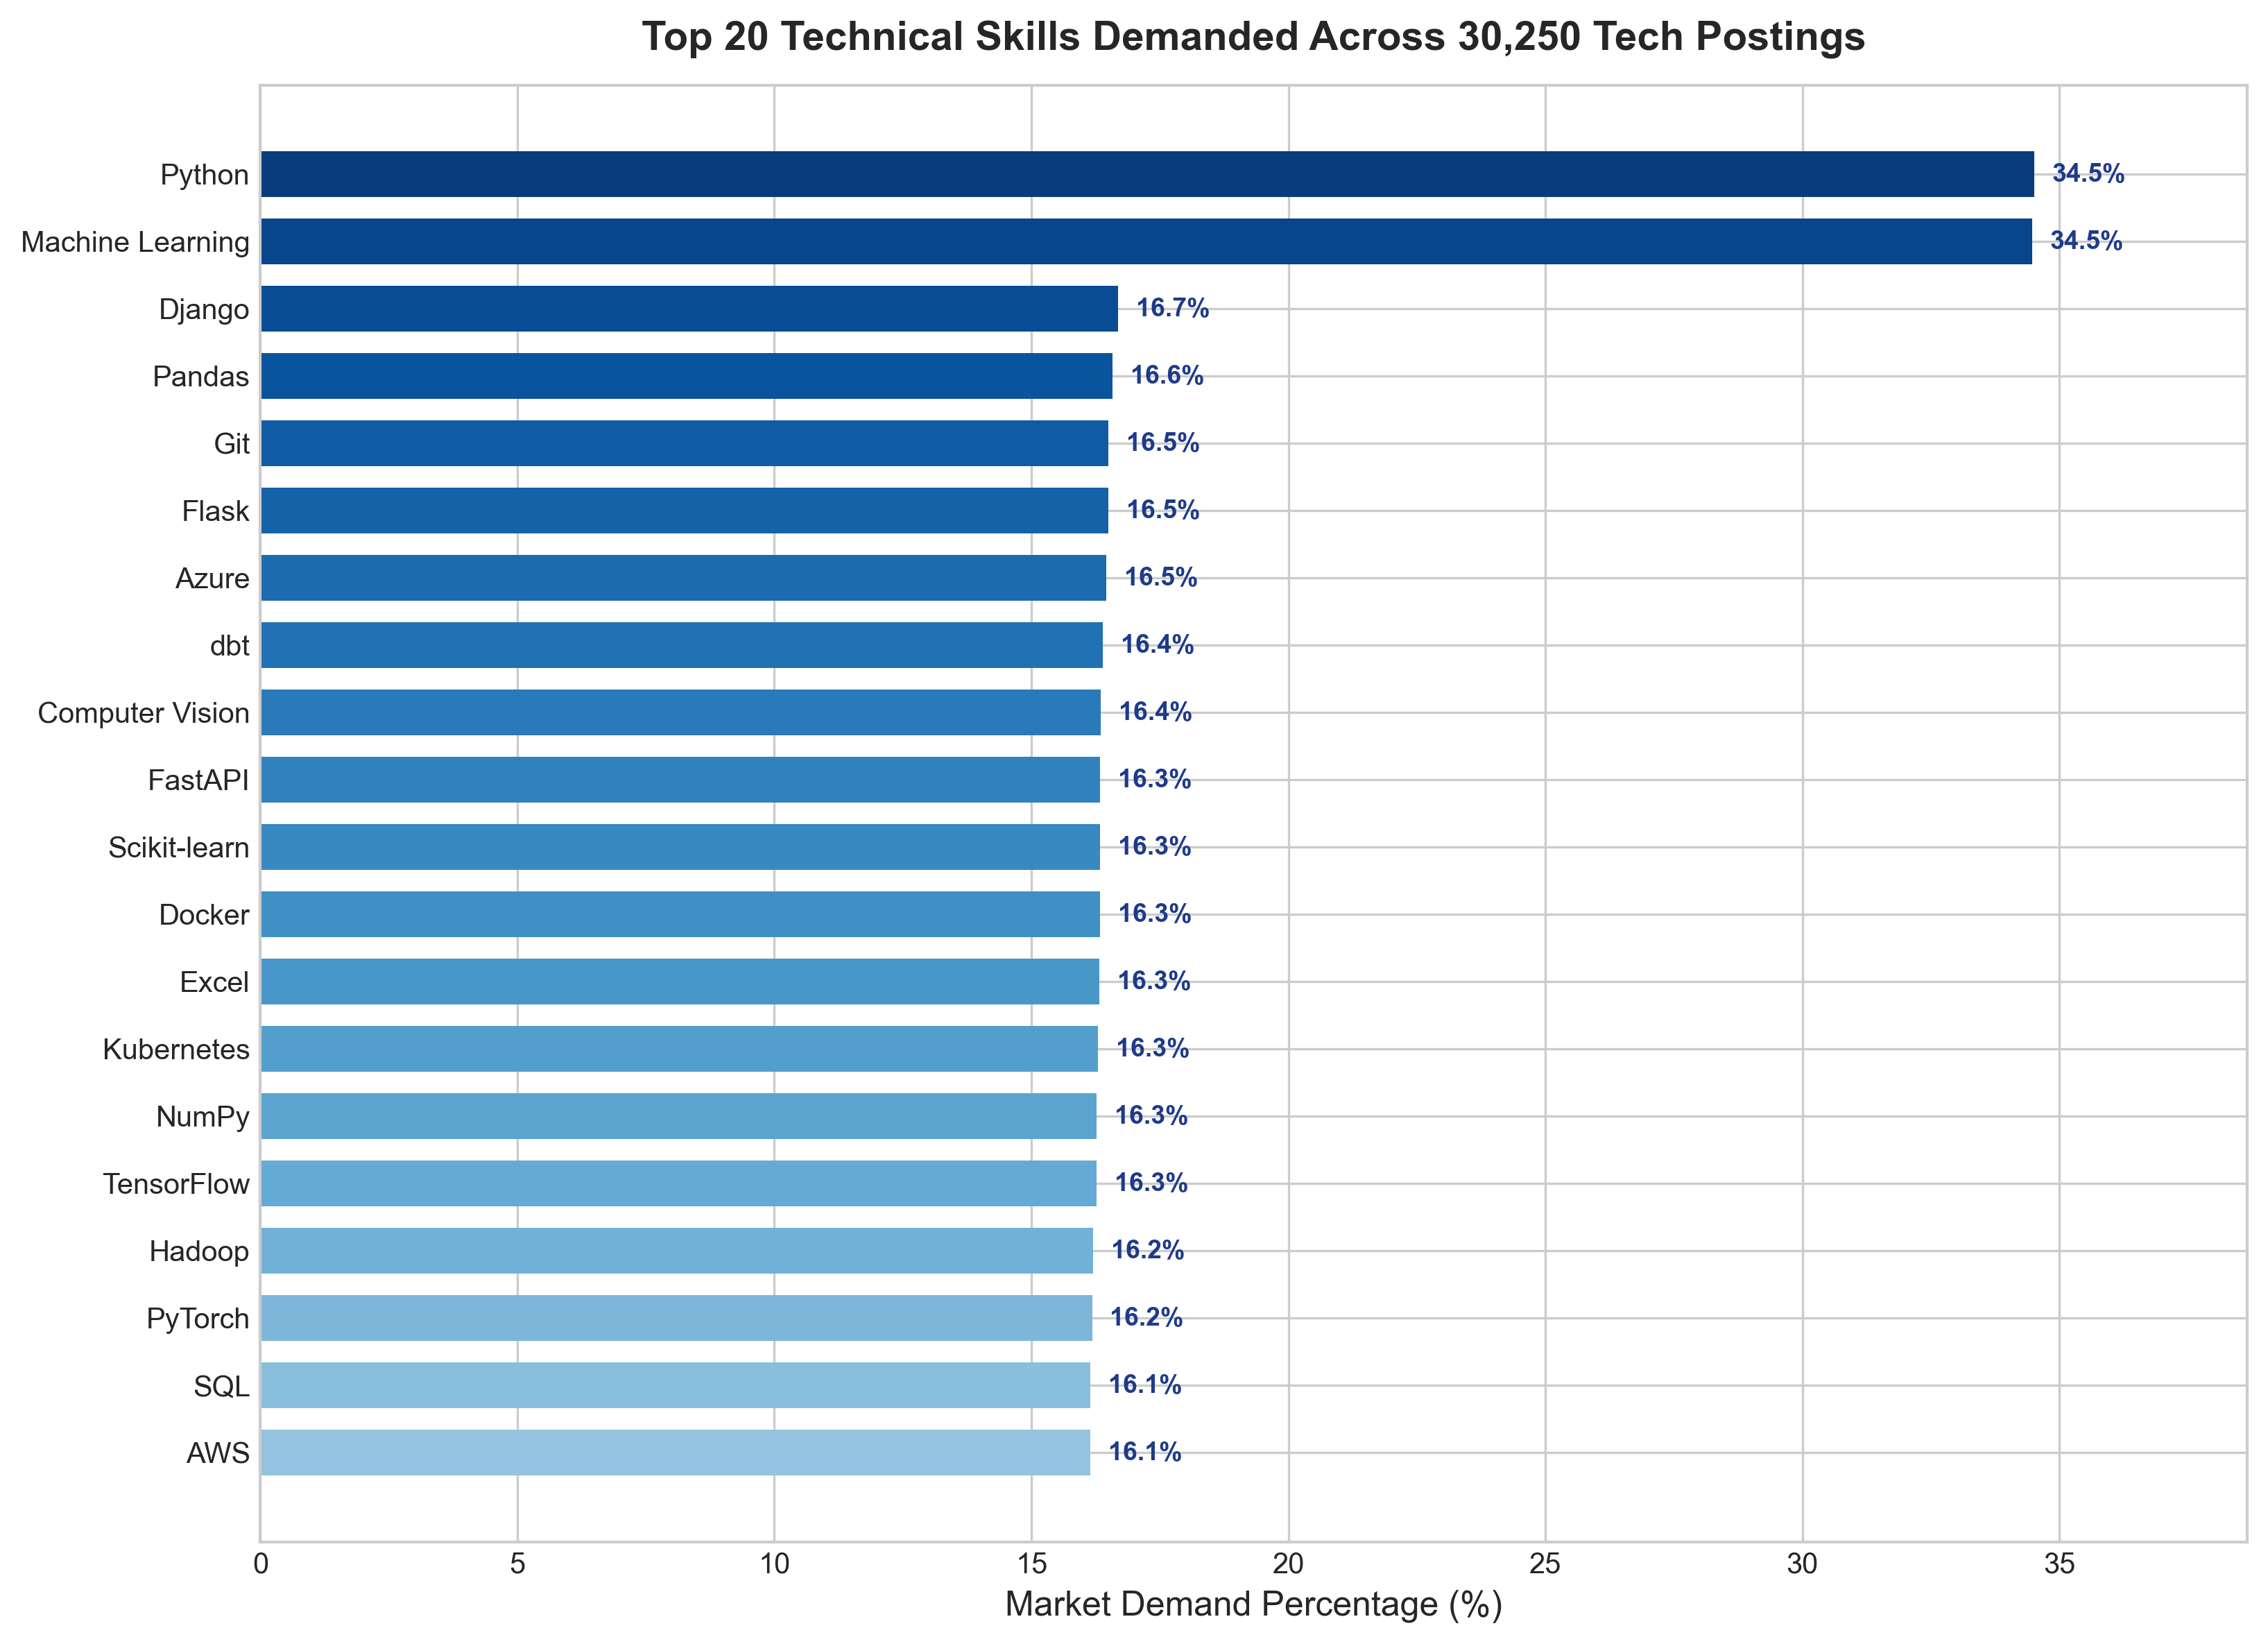

In [4]:
fig, ax = plt.subplots(figsize=(11, 8), dpi=300)
top20 = overall_demand.head(20).sort_values(by='demand_percentage', ascending=True)
colors = plt.cm.Blues(np.linspace(0.4, 0.95, len(top20)))
bars = ax.barh(top20['skill'], top20['demand_percentage'], color=colors, height=0.68)

ax.set_xlabel('Market Demand Percentage (%)', fontsize=12)
ax.set_title('Top 20 Technical Skills Demanded Across 30,250 Tech Postings', fontsize=14, fontweight='bold', pad=12)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.35, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold', color='#1E3A8A')
ax.set_xlim(0, max(top20['demand_percentage']) * 1.12)
plt.tight_layout()

figures_dir = os.path.join('..', 'reports', 'figures') if os.path.exists(os.path.join('..', 'reports', 'figures')) else os.path.join('reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)
fig.savefig(os.path.join(figures_dir, 'market_skill_demand_top20.png'))
plt.show()

### 5. Role-Specific Skill Requirements Analysis
Examining skill distributions for target roles (e.g. Data Scientist, Cloud Engineer, Software Engineer) categorized into Essential ($\ge 50\%$), Important ($25\% - 50\%$), and Additional ($< 25\%$).

In [5]:
target_role = 'Data Scientist'
role_skills = get_role_required_skills(target_role, df=df)
role_skills_df = pd.DataFrame(role_skills)

print(f'=== Skill Requirements for {target_role} (N = {len(df[df["clean_role"] == target_role]):,}) ===')
print(f'Total Skills Observed: {len(role_skills_df)}')
print(f'Essential Skills (>= 50%): {role_skills_df[role_skills_df["category"] == "Essential"]["skill"].tolist()}')
print(f'Important Skills (25-50%): {role_skills_df[role_skills_df["category"] == "Important"]["skill"].tolist()}')
print('\nTop 12 Skills Breakdown:')
role_skills_df.head(12)

=== Skill Requirements for Data Scientist (N = 2,497) ===
Total Skills Observed: 32
Essential Skills (>= 50%): ['Machine Learning', 'Python']
Important Skills (25-50%): []

Top 12 Skills Breakdown:


,skill,job_count,demand_percentage,category
0,Machine Learning,1786,71.53,Essential
1,Python,1776,71.13,Essential
2,Django,466,18.66,Additional
3,Pandas,442,17.70,Additional
4,Docker,424,16.98,Additional
5,SQL,423,16.94,Additional
6,Git,417,16.70,Additional
7,NumPy,414,16.58,Additional
8,JavaScript,413,16.54,Additional
9,AWS,413,16.54,Additional


### 6. Candidate Skill Extraction from Resume
Extracting candidate skills from a realistic candidate resume text using Module 3's `extract_skills_from_text`.

In [6]:
candidate_resume_text = '''
Vikram Malhotra
Bengaluru, India | vikram.sample@example.com

PROFESSIONAL SUMMARY
Data Analyst with 3 years of experience specializing in SQL querying, Python scripting, and business reporting.

TECHNICAL SKILLS
Languages: Python, SQL
Libraries & Tools: Pandas, NumPy, Excel, Power BI, Git

WORK EXPERIENCE
Analytics Specialist | Retail Dynamics (2021 - Present)
- Automated weekly executive KPI dashboards using Power BI and Excel.
- Built data extraction scripts in Python and optimized SQL queries on PostgreSQL.
'''

candidate_skills = extract_skills_from_text(candidate_resume_text)
print(f'Extracted Candidate Skills ({len(candidate_skills)}): {candidate_skills}')

Extracted Candidate Skills (8): ['Excel', 'Git', 'NumPy', 'Pandas', 'PostgreSQL', 'Power BI', 'Python', 'SQL']


### 7. Candidate Skill Comparison & Demand-Weighted Match Scoring
Evaluating the candidate's skills against the target role requirements using demand-weighted scoring.

In [7]:
comparison = compare_candidate_skills(candidate_skills, target_role, df=df)
match_score = calculate_skill_match_score(candidate_skills, target_role, df=df)

print(f'Target Role: {target_role}')
print(f'Demand-Weighted Skill Match Score: {match_score:.2f}%')
print(f'Matched Skills ({len(comparison["matched_skills"])}): {comparison["matched_skills"]}')
print(f'Missing Essential Skills ({len(comparison["missing_essential_skills"])}): {comparison["missing_essential_skills"]}')
print(f'Missing Important Skills ({len(comparison["missing_important_skills"])}): {comparison["missing_important_skills"]}')
print(f'Missing Additional Skills Count: {len(comparison["missing_additional_skills"])}')

Target Role: Data Scientist
Demand-Weighted Skill Match Score: 27.22%
Matched Skills (7): ['Python', 'Pandas', 'SQL', 'Git', 'NumPy', 'Excel', 'Power BI']
Missing Essential Skills (1): ['Machine Learning']
Missing Important Skills (0): []
Missing Additional Skills Count: 24


### 8. Prioritized Personalized Learning Recommendations
Generating prioritized learning actions and project practice recommendations for missing skills.

In [8]:
recommendations = generate_learning_recommendations(candidate_skills, target_role, df=df)
recs_df = pd.DataFrame(recommendations)

print(f'=== Personalized Learning Pathways for {target_role} ===\n')
for idx, row in recs_df.head(6).iterrows():
    print(f'[{row["priority"].upper()}] Skill: {row["skill"]} (Market Demand: {row["demand_percentage"]:.1f}%)')
    print(f'  Learning Action:  {row["suggested_learning_action"]}')
    print(f'  Project Practice: {row["suggested_project_practice"]}\n')

=== Personalized Learning Pathways for Data Scientist ===

[ESSENTIAL] Skill: Machine Learning (Market Demand: 71.5%)
  Learning Action:  Study supervised and unsupervised algorithms, cross-validation, and metric evaluation with Scikit-learn.
  Project Practice: Build and tune an end-to-end regression/classification pipeline with cross-validated hyperparameter search.

[ADDITIONAL] Skill: Django (Market Demand: 18.7%)
  Learning Action:  Learn Django ORM, authentication system, class-based views, and Django REST Framework (DRF).
  Project Practice: Create a full-featured web app with relational models, user authentication, and admin dashboard.

[ADDITIONAL] Skill: Docker (Market Demand: 17.0%)
  Learning Action:  Master containerization, multi-stage Dockerfiles, image caching, and volume mapping.
  Project Practice: Containerize a multi-service web application (FastAPI + PostgreSQL + Redis) using Docker Compose.

[ADDITIONAL] Skill: JavaScript (Market Demand: 16.5%)
  Learning Action: 

### 9. Visualizing Matched vs. Missing Skills
Generating a visual diagnostic chart comparing the candidate's matched skills versus missing skills ordered by market demand.

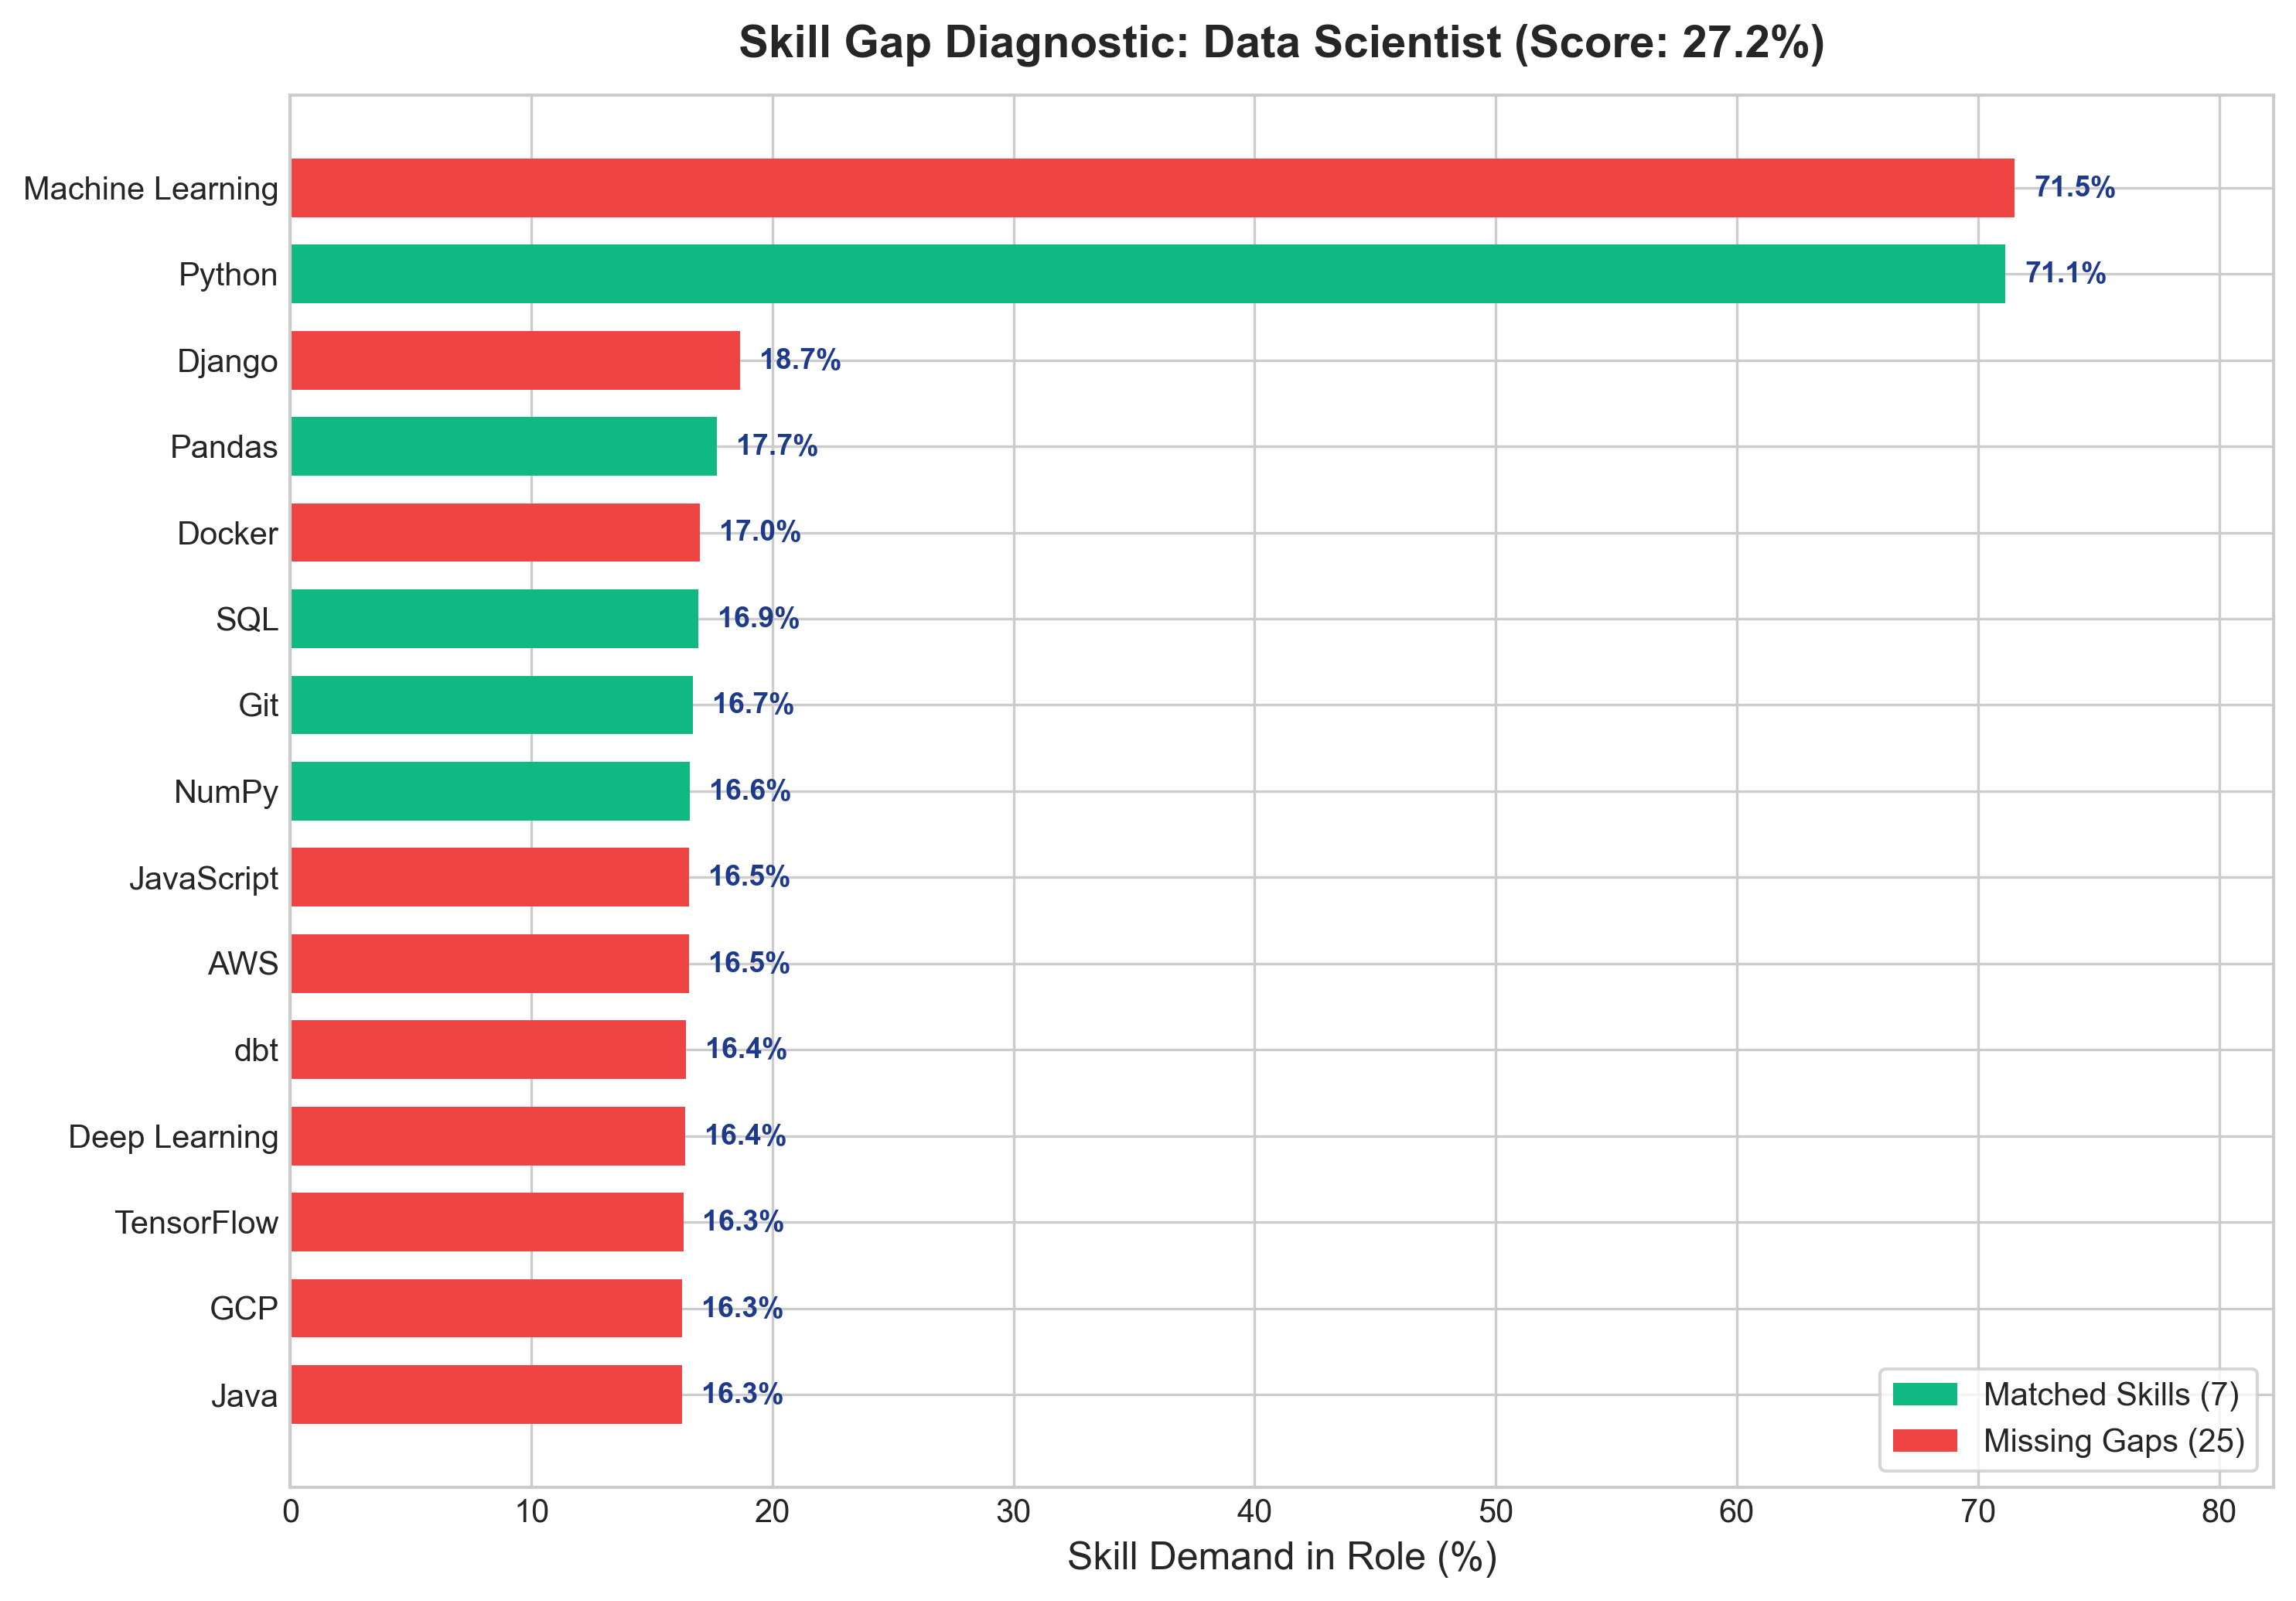

In [9]:
# Visualize top 15 role skills with Matched/Missing status
top15_role_skills = role_skills_df.head(15).copy()
top15_role_skills['status'] = top15_role_skills['skill'].apply(
    lambda s: 'Matched' if s in candidate_skills else 'Missing Gap'
)
top15_role_skills = top15_role_skills.sort_values(by='demand_percentage', ascending=True)

fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
colors = ['#10B981' if st == 'Matched' else '#EF4444' for st in top15_role_skills['status']]
bars = ax.barh(top15_role_skills['skill'], top15_role_skills['demand_percentage'], color=colors, height=0.68)

ax.set_xlabel('Skill Demand in Role (%)', fontsize=12)
ax.set_title(f'Skill Gap Diagnostic: {target_role} (Score: {match_score:.1f}%)', fontsize=14, fontweight='bold', pad=12)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#10B981', label=f'Matched Skills ({len(comparison["matched_skills"])})'),
    Patch(facecolor='#EF4444', label=f'Missing Gaps ({len(comparison["missing_skills"])})')
]
ax.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='white')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold', color='#1E3A8A')

ax.set_xlim(0, max(top15_role_skills['demand_percentage']) * 1.15)
plt.tight_layout()
fig.savefig(os.path.join(figures_dir, 'skill_gap_match_comparison.png'))
plt.show()

### 10. Complete Structured Skill Gap Report Generation
Executing `generate_skill_gap_report` to generate the complete JSON report.

In [10]:
complete_report = generate_skill_gap_report(
    candidate_skills=candidate_skills,
    job_role=target_role,
    df=df
)

print('=== Complete Structured Skill Gap Report ===')
summary_keys = [
    'job_role', 'skill_match_score', 'total_required_skills',
    'matched_skills', 'missing_essential_skills',
    'essential_match_count', 'essential_missing_count'
]
for k in summary_keys:
    print(f'  {k}: {complete_report[k]}')

print(f'\nTotal Learning Recommendations Generated: {len(complete_report["learning_recommendations"])}')
print(f'Warnings: {complete_report["analysis_warnings"]}')

=== Complete Structured Skill Gap Report ===
  job_role: Data Scientist
  skill_match_score: 27.22
  total_required_skills: 32
  matched_skills: ['Python', 'Pandas', 'SQL', 'Git', 'NumPy', 'Excel', 'Power BI']
  missing_essential_skills: ['Machine Learning']
  essential_match_count: 1
  essential_missing_count: 1

Total Learning Recommendations Generated: 25
Warnings: []


### 11. Findings & Governance Notes

1. **Demand-Weighted Match Accuracy:** Weighting skills by market demand percentage ensures that missing core requirements (e.g. `Machine Learning` for Data Scientist at $71.5\%$) appropriately impacts the match score more than niche secondary tools ($16\%$).
2. **Dynamic Role Sourcing:** Roles and requirements are queried dynamically from the 30,250 job posting dataset rather than being static or hardcoded.
3. **Ethical Responsible AI Statement:** The skill match score reflects alignment with technical requirements in historical job postings. It does not represent an employability guarantee, candidate quality rating, or predictive hiring probability.